# Part 4.1: stock-flow scenarios for 2030 and 2035

These are **scenarios, not forecasts**. Part 2 showed that statistical forecasts of the burden are worth quoting only a year or two ahead,
so for 2030 and 2035 we ask a different question: *what would the number of renter households, and of extremely low income (ELI) renter
households, be if population by age follows the Cooper Center projection and renting behaves in a stated way?* (`src/scenarios.py`)

* Renter households by age of householder (ACS 2022-24 mean, eight age bands) grow with the Cooper population in the same band, so with
  constant rates they change only through population aging and growth. 2023, the center of the ACS window, and **2035 are interpolated**
  from the Cooper years (2020, 2030, 2040); 2035 is therefore an interpolation and says so.
* ELI renters = renter households times the CHAS 2018-2022 ELI share of renters.
* **Baseline** keeps the age-specific renter rates and the ELI share constant. **Low** and **high** let both drift every year at the 10th and 90th
  percentile of how fast they drifted across states in the past (renter rates 2015 to 2023; ELI share, CHAS 2010-14 to 2018-22). They are
  bounds built from history, applied to every state at once, not confidence intervals.

The notebook first checks the mechanics against the past, then shows the scenarios.

In [1]:
import sys
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import scenarios as S
from viz import apply_style, SERIES, save_figure, SURFACE, MUTED, BASELINE, INK_2, dot, end_label, tile_map, SEQUENTIAL, DIVERGING

apply_style()
pd.set_option("display.width", 220)
acs, cooper, chas, panel = S.load_inputs()
abbr = panel.groupby("state_fips").state_abbr.first()
names = panel.groupby("state_fips").state_name.first()
SCEN = {"baseline": SERIES[0], "low": SERIES[2], "high": SERIES[1]}

## 1. Does the mechanism describe the past?

Hindcast: apply each state's **2014-16 age-specific renter rates** to the **actual 2022-24 age structure** (ACS) and compare the implied growth in
renter households with the actual growth between the 2015 and 2023 window centers. If age structure and growth mattered little, a model of "no
change" would do as well.

,mean actual growth %,"age structure, constant rates %",population growth only %
0,3.94,5.96,6.41


,"state MAE, pp",correlation with actual
"age structure, constant rates",3.86,0.57
population growth only,4.11,0.54
no change,5.29,NaN


constant rates overpredict renter household growth by 2.0 points on average over the eight years


C:\Users\erick\AppData\Local\Temp\ipykernel_36176\1446508888.py:22: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


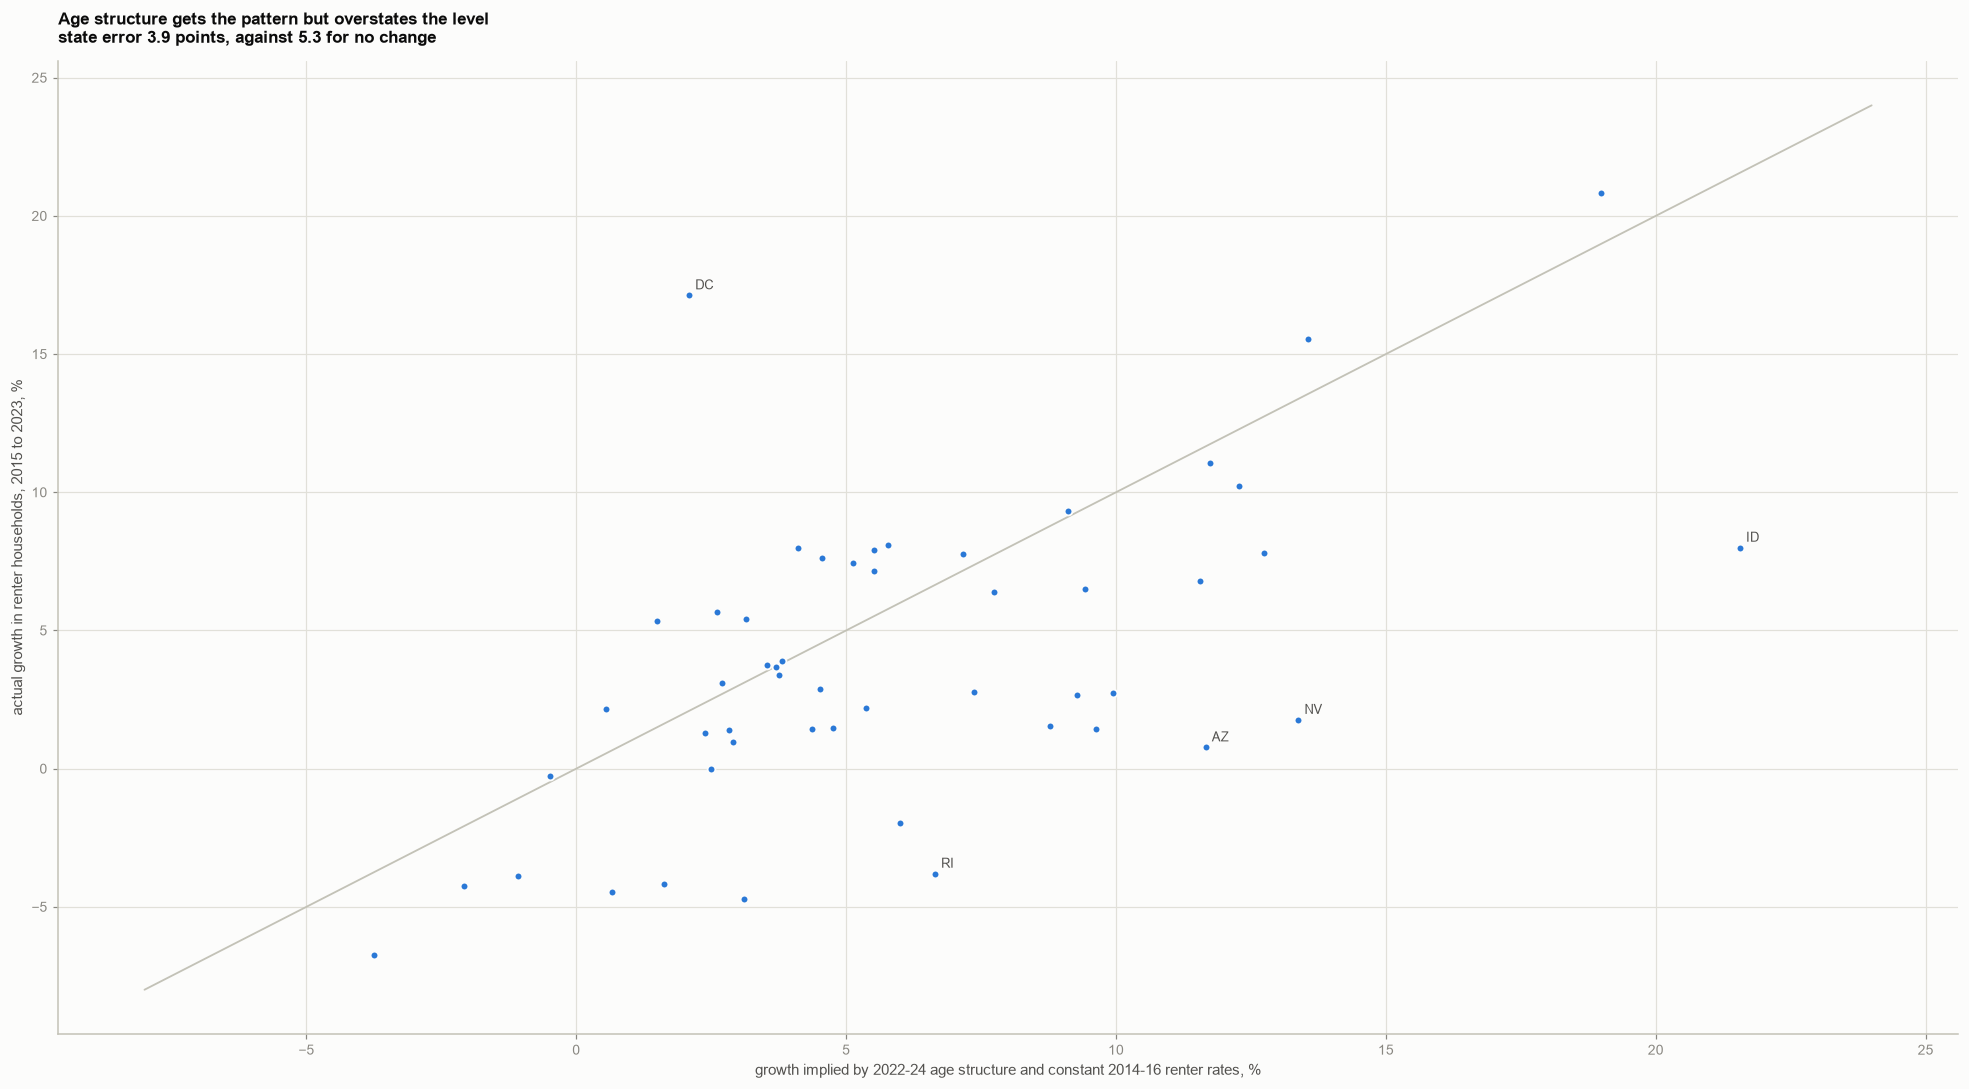

In [2]:
h = S.hindcast(acs)
res = pd.DataFrame({"mean actual growth %": [h.actual_growth_pct.mean()], "age structure, constant rates %": [h.age_rates_growth_pct.mean()],
                    "population growth only %": [h.population_only_growth_pct.mean()]})
display(res.round(2))
cmp = pd.DataFrame({"state MAE, pp": [(h.age_rates_growth_pct - h.actual_growth_pct).abs().mean(), (h.population_only_growth_pct - h.actual_growth_pct).abs().mean(), h.actual_growth_pct.abs().mean()],
                    "correlation with actual": [h.age_rates_growth_pct.corr(h.actual_growth_pct), h.population_only_growth_pct.corr(h.actual_growth_pct), np.nan]},
                   index=["age structure, constant rates", "population growth only", "no change"])
display(cmp.round(2))
mae_age, mae_zero = cmp.iloc[0, 0], cmp.iloc[2, 0]
over = (h.age_rates_growth_pct - h.actual_growth_pct).mean()
print(f"constant rates overpredict renter household growth by {over:.1f} points on average over the eight years")

fig, ax = plt.subplots(figsize=(18, 10))
ax.plot([-8, 24], [-8, 24], color=BASELINE, lw=1.2, zorder=1)
ax.scatter(h.age_rates_growth_pct, h.actual_growth_pct, s=26, color=SERIES[0], edgecolor=SURFACE, linewidth=1.2, zorder=3)
res_abs = (h.age_rates_growth_pct - h.actual_growth_pct).abs().sort_values(ascending=False).head(5).index
for s in res_abs:
    ax.annotate(abbr[s], (h.age_rates_growth_pct[s], h.actual_growth_pct[s]), xytext=(4, 4), textcoords="offset points", fontsize=8.5, color=INK_2)
ax.set_xlabel("growth implied by 2022-24 age structure and constant 2014-16 renter rates, %")
ax.set_ylabel("actual growth in renter households, 2015 to 2023, %")
ax.set_title(f"Age structure gets the pattern but overstates the level\nstate error {mae_age:.1f} points, against {mae_zero:.1f} for no change", fontsize=11, loc="left")
fig.tight_layout()
save_figure(fig, "41_hindcast", part="04_scenarios")
plt.show()

## 2. How fast did renting and the ELI share drift?

The low and high scenarios use the 10th and 90th percentiles of these state drifts. A negative drift means fewer renter households than age
structure alone implies (the rate effect) or a smaller ELI share of renters.

In [3]:
drift = S.historical_drift(acs, chas)
q = drift[["g_rate", "g_eli"]].quantile([0.1, 0.25, 0.5, 0.75, 0.9]) * 100
q.columns = ["renter rate drift, % per year", "ELI share drift, % per year"]
display(q.round(2))
scen = S.drift_scenarios(drift)
print({k: (round(v[0] * 100, 2), round(v[1] * 100, 2)) for k, v in scen.items()})
pct0_rate = (drift.g_rate < 0).mean(); pct0_eli = (drift.g_eli < 0).mean()
print(f"states where the renter rate drifted down: {pct0_rate:.0%}; where the ELI share drifted down: {pct0_eli:.0%}")

,"renter rate drift, % per year","ELI share drift, % per year"
0.10,-0.97,-1.50
0.25,-0.55,-1.14
0.50,-0.20,-0.73
0.75,0.13,-0.09
0.90,0.28,0.11


{'baseline': (0.0, 0.0), 'low': (np.float64(-0.97), np.float64(-1.5)), 'high': (np.float64(0.28), np.float64(0.11))}
states where the renter rate drifted down: 63%; where the ELI share drifted down: 80%


Both drifted down in most states, so the constant-rate baseline sits near the **top** of the historical range, not in the middle. A fourth reference
case that repeats the *median* historical drift is computed below as a check; it is not one of the three scenarios.

## 3. National totals

In [4]:
proj = S.project(acs, cooper, chas)
med = {"median drift": (float(drift.g_rate.median()), float(drift.g_eli.median()))}
ref = S.project(acs, cooper, chas, scenarios=med)
tot = pd.concat([proj, ref]).groupby(["scenario", "year"])[["renter_hh", "eli_renters"]].sum().div(1e6).unstack("year")
tot = tot.reindex(["baseline", "high", "low", "median drift"])
tot.columns = [f"{a} {b}" for a, b in tot.columns]
display(tot.round(2))
b = proj[proj.scenario == "baseline"].groupby("year")[["renter_hh", "eli_renters"]].sum()
print("baseline change 2023 to 2030 and 2035, renter households:", (b.renter_hh.loc[[2030, 2035]] / b.renter_hh.loc[2023] - 1).mul(100).round(1).to_dict(),
      "| ELI renters:", (b.eli_renters.loc[[2030, 2035]] / b.eli_renters.loc[2023] - 1).mul(100).round(1).to_dict())

,renter_hh 2023,renter_hh 2030,renter_hh 2035,eli_renters 2023,eli_renters 2030,eli_renters 2035
scenario,,,,,,
baseline,45.66,47.91,48.71,10.92,11.41,11.57
high,45.66,48.87,50.38,10.92,11.73,12.12
low,45.66,44.75,43.33,10.92,9.60,8.60
median drift,45.66,47.25,47.57,10.92,10.70,10.35


baseline change 2023 to 2030 and 2035, renter households: {2030: 4.9, 2035: 6.7} | ELI renters: {2030: 4.5, 2035: 6.0}


C:\Users\erick\AppData\Local\Temp\ipykernel_36176\3361958312.py:11: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


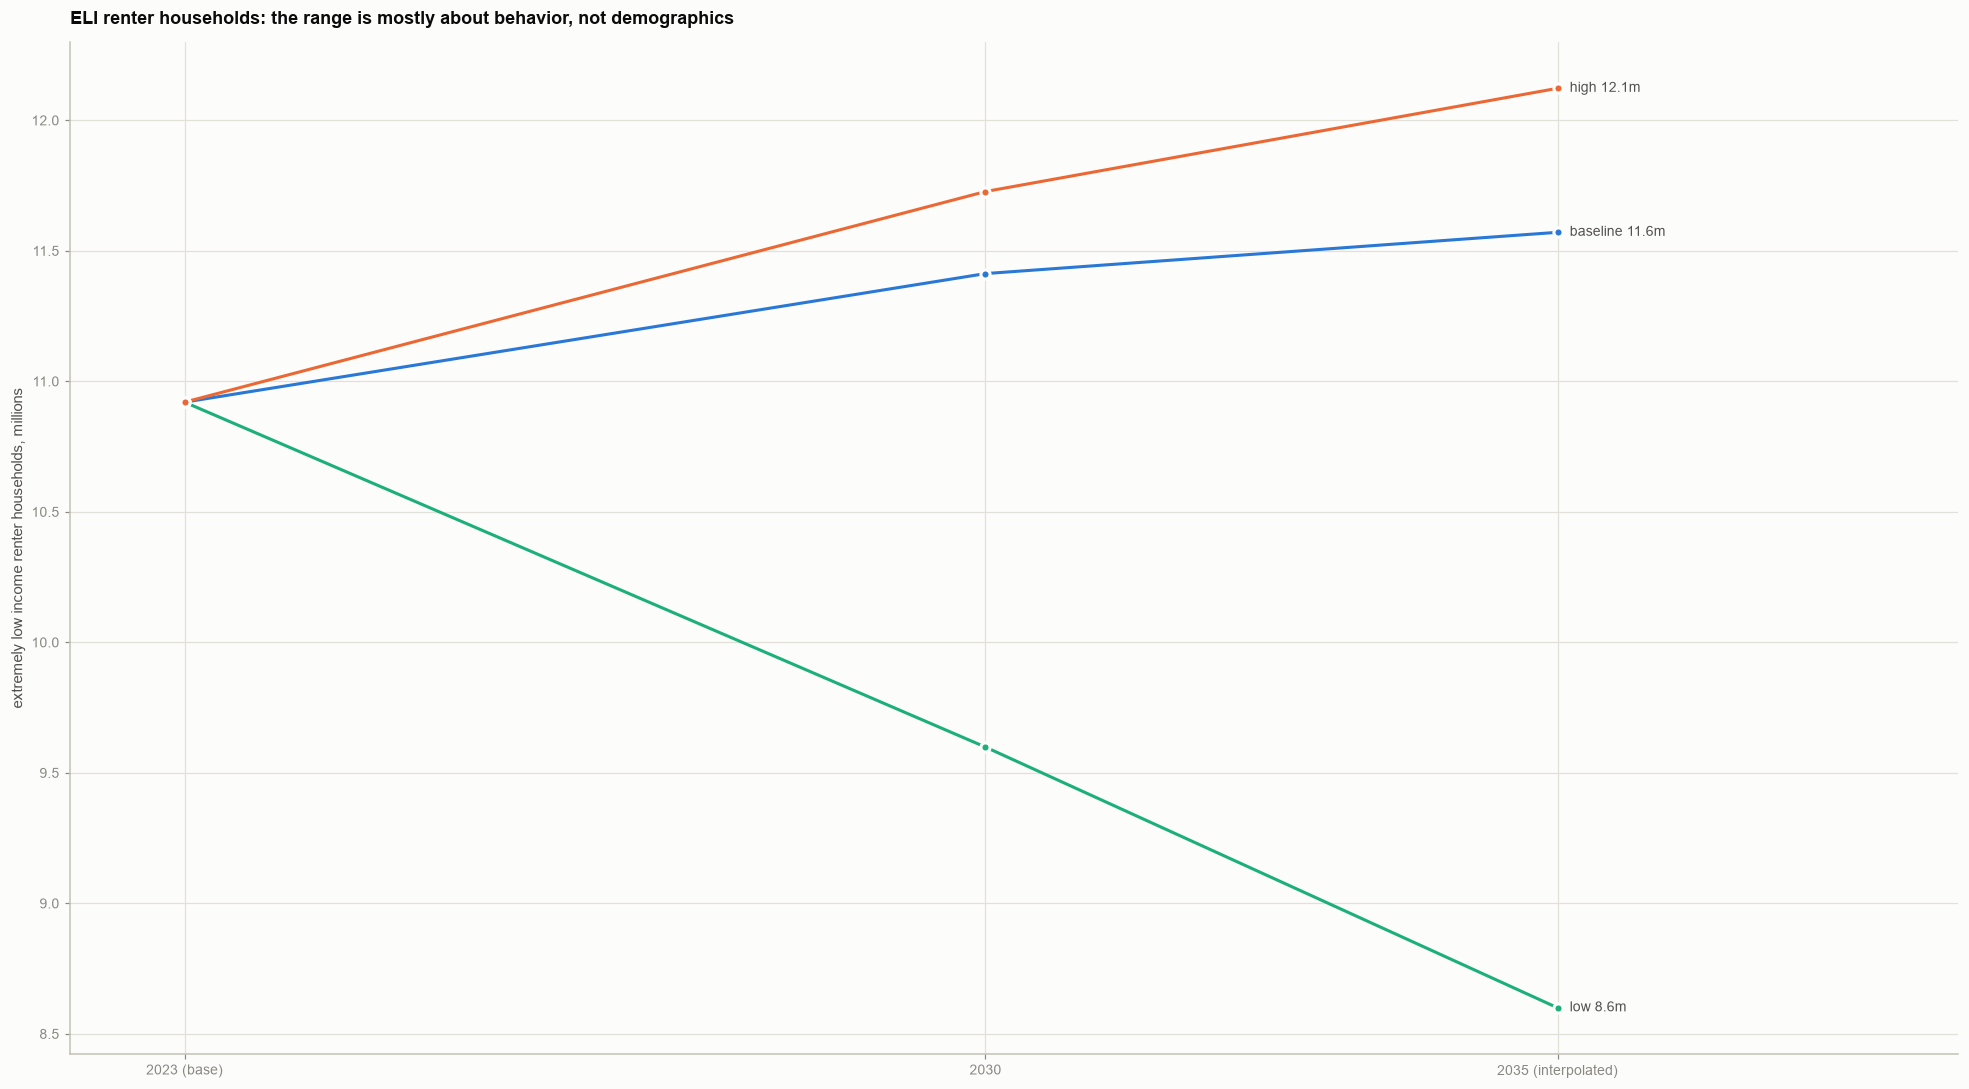

In [5]:
fig, ax = plt.subplots(figsize=(18, 10))
for name, color in SCEN.items():
    d = proj[proj.scenario == name].groupby("year").eli_renters.sum() / 1e6
    ax.plot(d.index, d.values, color=color, marker=None)
    for y, v in d.items():
        dot(ax, y, v, color)
    end_label(ax, 2035, d.iloc[-1], f"{name} {d.iloc[-1]:.1f}m", dx=8)
ax.set_xticks([2023, 2030, 2035], ["2023 (base)", "2030", "2035 (interpolated)"])
ax.set_xlim(2022, 2038.5); ax.set_ylabel("extremely low income renter households, millions")
ax.set_title("ELI renter households: the range is mostly about behavior, not demographics", fontsize=11.5, loc="left")
fig.tight_layout()
save_figure(fig, "41_national_scenarios", part="04_scenarios")
plt.show()

## 4. States

Percent change in ELI renter households from 2023 to 2035. The baseline is driven only by population by age; the low and high ends add the historical
drift of renting and of the ELI share.

In [6]:
need = S.need_table(acs, cooper, chas, panel)
need["state"] = need.state_fips.map(abbr)
need.to_csv("outputs/tables/scenarios_state.csv", index=False)
p35 = need[need.year == 2035].pivot(index="state_fips", columns="scenario", values="eli_change_pct")
p35["state"] = p35.index.map(abbr)
base35 = need[(need.year == 2035) & (need.scenario == "baseline")].set_index("state_fips")
display(p35.sort_values("baseline", ascending=False).head(8).round(1))
display(p35.sort_values("baseline").head(6).round(1))
n_decline = int((p35.baseline < 0).sum())
print(f"baseline ELI renters fall in {n_decline} states and rise in {51 - n_decline}; baseline range {p35.baseline.min():.1f} to {p35.baseline.max():.1f} percent; "
      f"the ELI count rises under even the low scenario in {int((p35.low > 0).sum())} states")

scenario,baseline,high,low,state
state_fips,,,,
16,22.9,28.8,-8.6,ID
49,20.4,26.1,-10.5,UT
48,19.5,25.2,-11.2,TX
12,17.9,23.5,-12.4,FL
45,15.9,21.4,-13.8,SC
04,13.8,19.3,-15.4,AZ
37,13.8,19.3,-15.4,NC
10,13.6,19.0,-15.6,DE


scenario,baseline,high,low,state
state_fips,,,,
54,-5.6,-1.1,-29.8,WV
28,-2.5,2.2,-27.5,MS
17,-2.4,2.3,-27.5,IL
22,-2.4,2.3,-27.4,LA
15,-1.3,3.4,-26.7,HI
36,-0.4,4.4,-26.0,NY


baseline ELI renters fall in 8 states and rise in 43; baseline range -5.6 to 22.9 percent; the ELI count rises under even the low scenario in 0 states


C:\Users\erick\AppData\Local\Temp\ipykernel_36176\1737246155.py:12: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


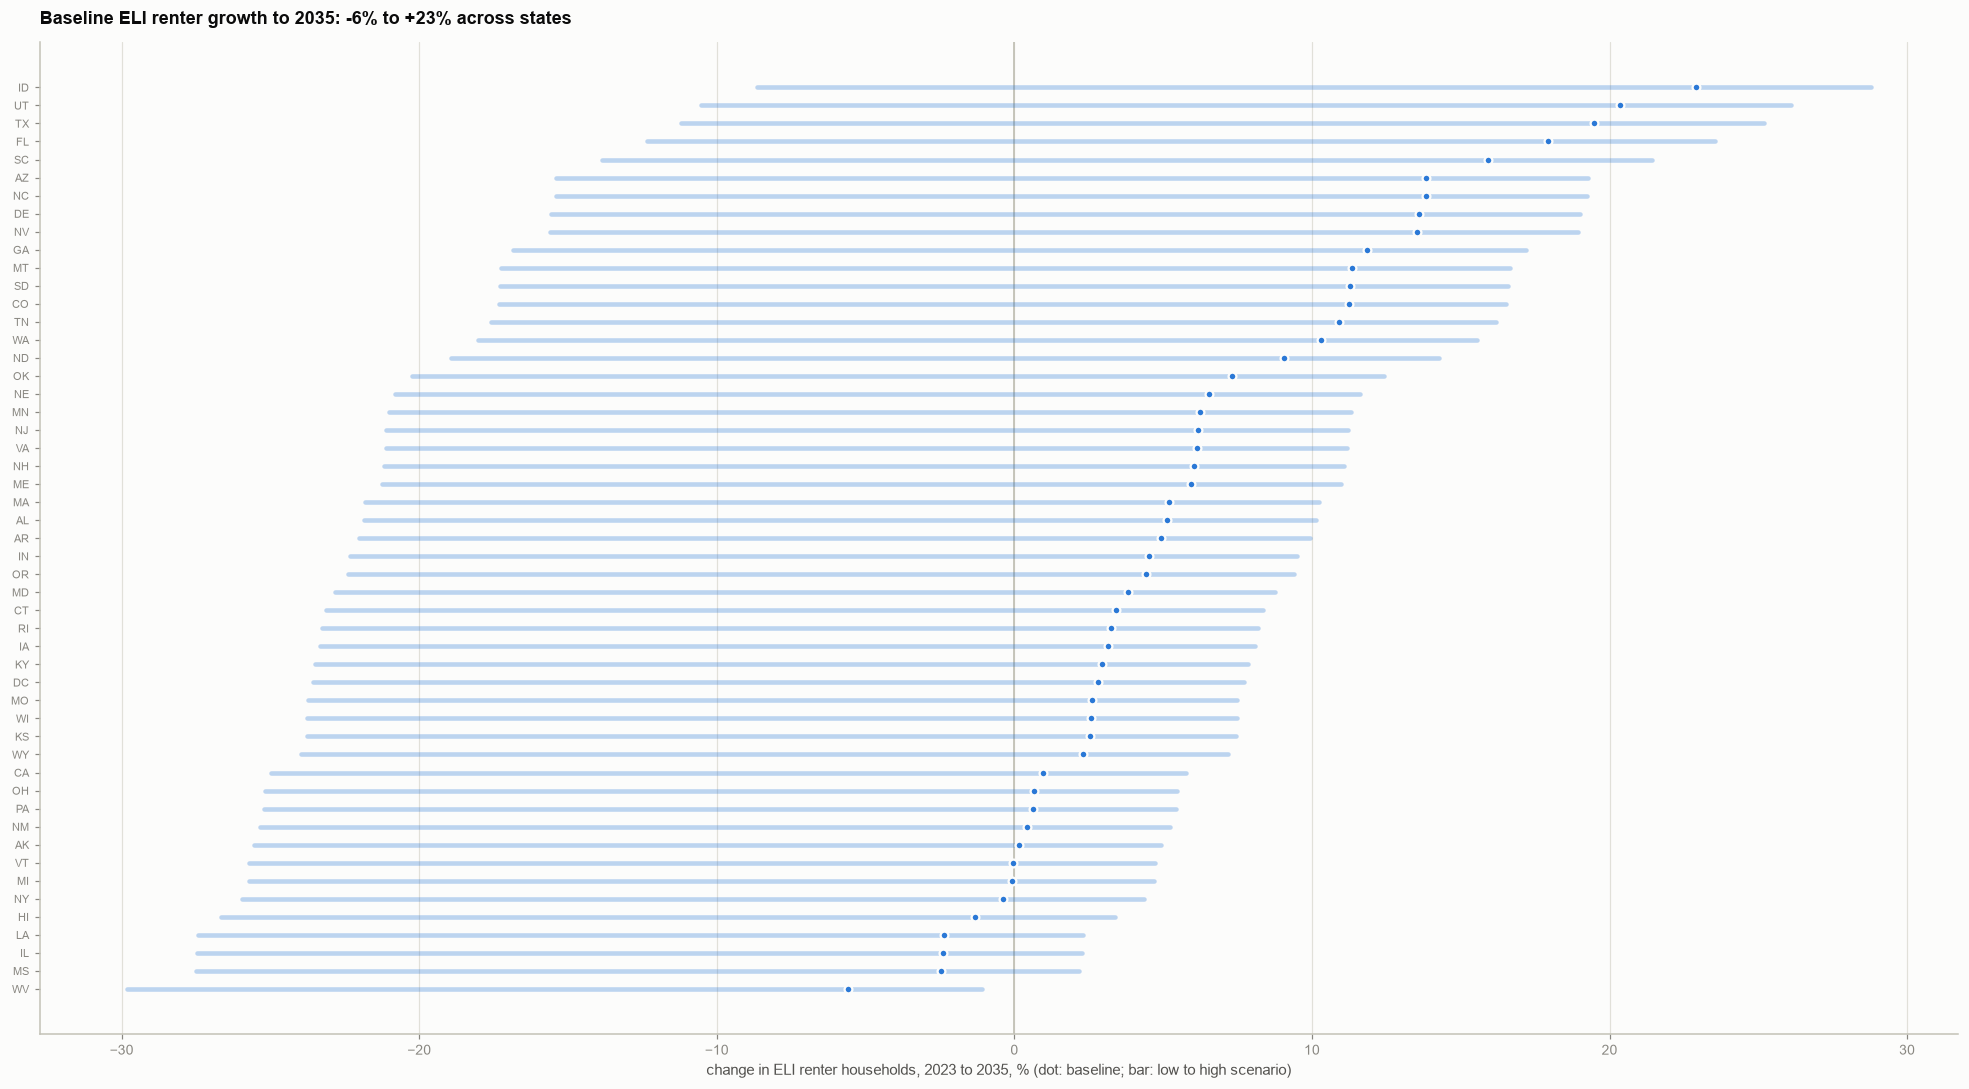

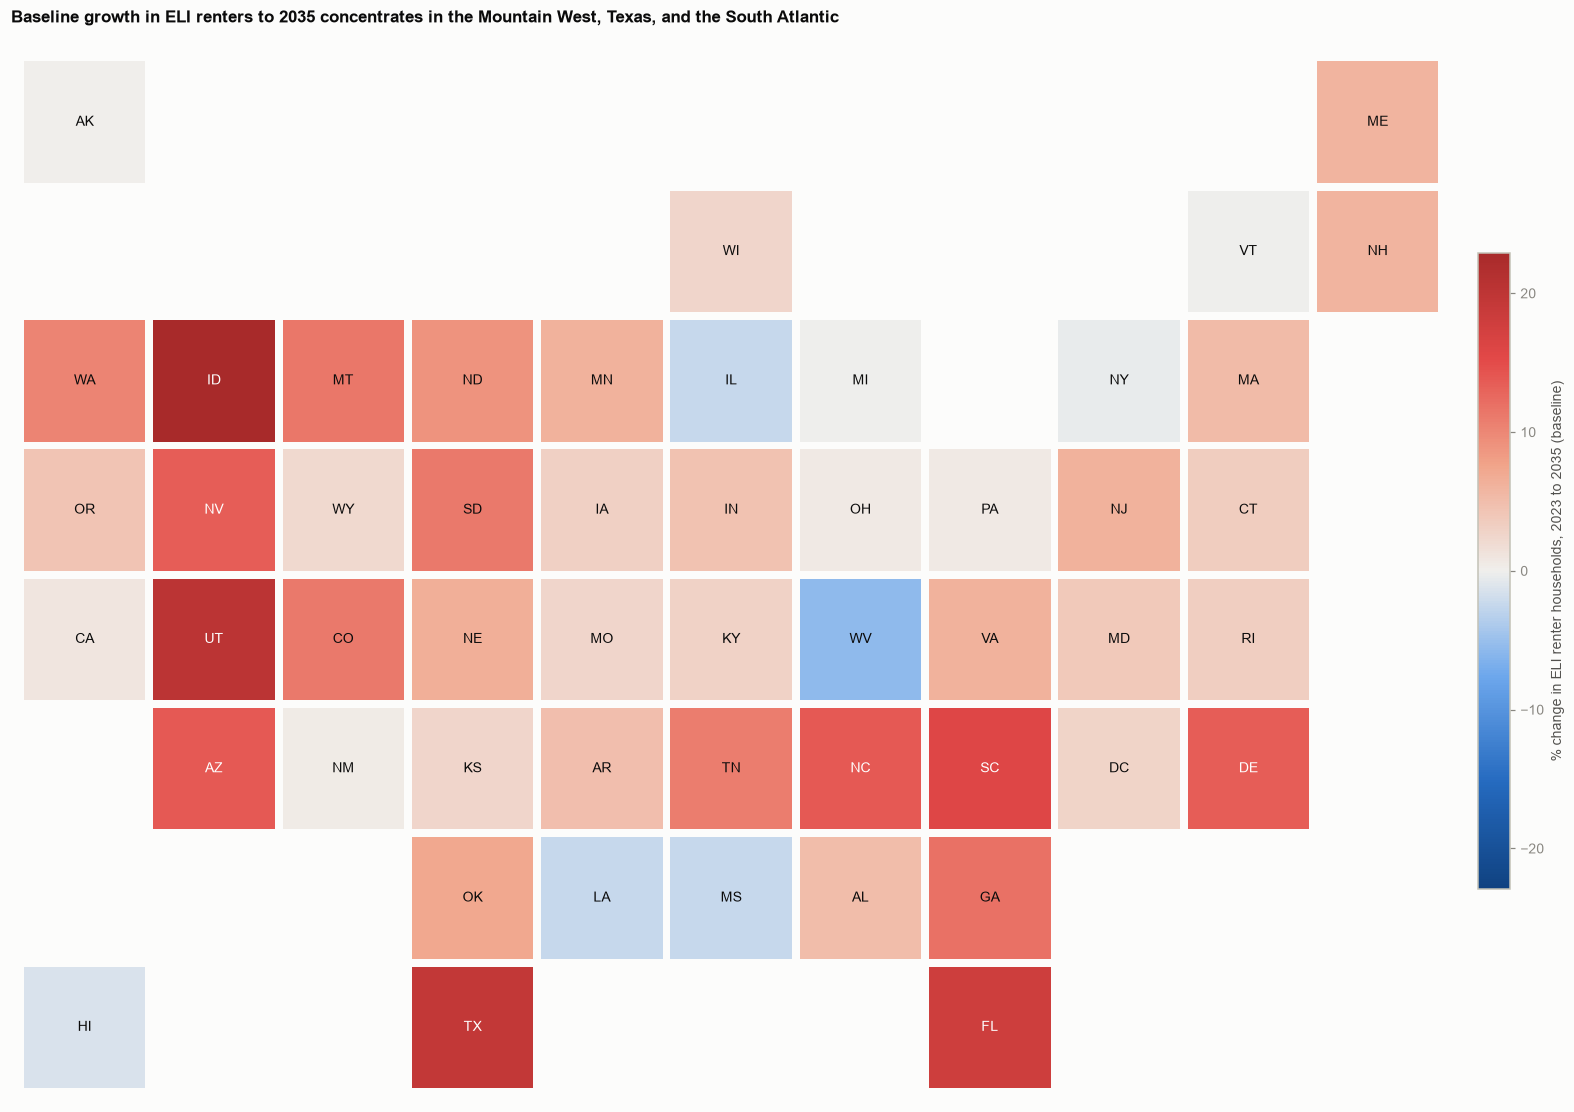

In [7]:
order = p35.sort_values("baseline").index.tolist()
fig, ax = plt.subplots(figsize=(18, 10))
ys = np.arange(len(order))
ax.axvline(0, color=BASELINE, lw=1.2, zorder=1)
for yi, s in zip(ys, order):
    ax.plot([p35.loc[s, "low"], p35.loc[s, "high"]], [yi, yi], color=SERIES[0], alpha=0.3, lw=3, solid_capstyle="round", zorder=2)
ax.scatter(p35.loc[order, "baseline"], ys, s=26, color=SERIES[0], edgecolor=SURFACE, linewidth=1.5, zorder=3)
ax.set_yticks(ys, [abbr[s] for s in order], fontsize=7.5)
ax.set_xlabel("change in ELI renter households, 2023 to 2035, % (dot: baseline; bar: low to high scenario)")
ax.grid(axis="y", visible=False)
ax.set_title(f"Baseline ELI renter growth to 2035: {p35.baseline.min():.0f}% to {p35.baseline.max():+.0f}% across states", fontsize=11.5, loc="left")
fig.tight_layout()
save_figure(fig, "41_state_eli_change", part="04_scenarios")
plt.show()

fig, ax = plt.subplots(figsize=(18, 10))
vals = p35.set_index("state").baseline
m = tile_map(ax, vals, cmap=DIVERGING, vmin=-max(abs(vals.min()), vals.max()), vmax=max(abs(vals.min()), vals.max()))
cb = fig.colorbar(m, ax=ax, shrink=0.6, pad=0.01); cb.set_label("% change in ELI renter households, 2023 to 2035 (baseline)", fontsize=9)
ax.set_title("Baseline growth in ELI renters to 2035 concentrates in the Mountain West, Texas, and the South Atlantic", fontsize=11, loc="left")
save_figure(fig, "41_baseline_map", part="04_scenarios")
plt.show()

## Findings

**National picture.** Renter households are 45.7 million in 2023 (ACS 2022-24 mean). The baseline, which changes only through population aging and growth, gives
47.9 million in 2030 (+4.9 percent) and 48.7 million in 2035 (+6.7 percent). ELI renter households go from 10.9 million to 11.4 million (+4.5 percent) and
11.6 million (+6.0 percent): demographics alone add about 0.65 million ELI renter households by 2035. The high scenario reaches 12.1 million (+11 percent)
and the low scenario 8.6 million (-21 percent).

**The sign of the change depends on behavior, not demographics.** Renter rates drifted down in 63 percent of states between 2015 and 2023 (median -0.2 percent a year) and
the ELI share of renters drifted down in 80 percent (median -0.7 percent a year, CHAS 2010-14 to 2018-22). Repeating the *median* historical drift gives 10.4 million
ELI renters in 2035 (-5 percent), the opposite sign of the baseline. So the baseline sits near the upper end of what history suggests, not in the middle. The ELI drift comes from
a window ending in 2022 that mostly predates the 2022-23 rent increases (Part 1.3), so it may not continue; the data cannot say. The honest statement is that
the national ELI count in 2035 could plausibly be anywhere from about 8.6 to 12.1 million and the data cannot narrow it.

**State differences are demographic by construction.** The same national drift is applied to every state, so the ordering of states is identical in all three
scenarios and only the level shifts. Baseline change in ELI renters to 2035 runs from -5.6 percent (West Virginia) to +22.9 percent (Idaho); the largest rises are in Idaho, Utah,
Texas (+19.5), Florida (+17.9), South Carolina, Arizona, North Carolina, Delaware, and Nevada, and the baseline falls in eight states (West Virginia, Mississippi,
Illinois, Louisiana, Hawaii, New York, Michigan, Vermont). In absolute terms Texas (+169,000 ELI renter households) and Florida (+105,000) add the most, then North Carolina (+44,000)
and Georgia (+37,000) (`outputs/tables/scenarios_state.csv`). State-specific behavior, such as a state
whose renter rates move differently, is not modeled.

**Check on the mechanism.** Applying 2014-16 renter rates to the actual 2022-24 age structure overstated renter household growth between 2015 and 2023 by 2.0 points on average
(5.96 against 3.94 percent), a consequence of the downward drift above. It still beat no change on the state error (3.9 against 5.3 points) and narrowly beat population growth alone (4.1), with a
cross-state correlation of 0.57. So age structure captures part of the geographic pattern and overstates the level. DC (actual +17 percent against +2 implied) and Idaho (+8 against +22) are the
largest misses.

**What these scenarios do not include.** migration beyond the 2010-2020 cohort change ratios that Cooper's method carries forward (its 2030 totals extend 2010-2025 growth trends from the Census Bureau's 2025 estimate, and it gives no uncertainty range), changes in
the income distribution beyond the ELI share, new construction, losses of units, or any policy. The 2023 base and 2035 are interpolations of the Cooper years. Nothing here is a forecast, and none of it has
been validated beyond the hindcast above.